In [1]:
install.packages("tidyverse")

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)



In [2]:
library(tidyverse)

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.1.4     ✔ readr     2.1.6
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ ggplot2   4.0.1     ✔ tibble    3.3.0
✔ lubridate 1.9.4     ✔ tidyr     1.3.1
✔ purrr     1.2.0     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors


In [3]:
install.packages("nycflights13")

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)



In [ ]:
install.packages("Lahman") # Install Lahman package
library(Lahman) # Import Lahman package

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)



# Hoofdstuk 3 - Data Transformation with dplyr

We gaan een aantal technieken oefenen waarmee je data kunt manipuleren:<br>
- filteren = filter<br>
- herordenen = arrange<br>
- unieke waarden = distinct<br>
- selecteren = select<br>
- wijzigen = mutate<br>
- samenvatten = summarize or group by<br>

<p>
De dataset waarmee we deze oefeningen doen, is de nycflights13:<br>
een dataset met gegevens over alle vluchten die in 2013 zijn vertrokken vanuit New York City.

In [20]:
??nycflights13

Omdat we R-code draaien in een Python-omgeving, moeten we bij het verwijzen naar de dataset opletten dat de Python-omgeving de dataset herkent als een dataframe (tibble): nycflights::flights

In [5]:
nycflights13::flights

year,month,day,dep_time,sched_dep_time,dep_delay,arr_time,sched_arr_time,arr_delay,carrier,flight,tailnum,origin,dest,air_time,distance,hour,minute,time_hour
<int>,<int>,<int>,<int>,<int>,<dbl>,<int>,<int>,<dbl>,<chr>,<int>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dttm>
2013,1,1,517,515,2,830,819,11,UA,1545,N14228,EWR,IAH,227,1400,5,15,2013-01-01 05:00:00
2013,1,1,533,529,4,850,830,20,UA,1714,N24211,LGA,IAH,227,1416,5,29,2013-01-01 05:00:00
2013,1,1,542,540,2,923,850,33,AA,1141,N619AA,JFK,MIA,160,1089,5,40,2013-01-01 05:00:00
2013,1,1,544,545,-1,1004,1022,-18,B6,725,N804JB,JFK,BQN,183,1576,5,45,2013-01-01 05:00:00
2013,1,1,554,600,-6,812,837,-25,DL,461,N668DN,LGA,ATL,116,762,6,0,2013-01-01 06:00:00
2013,1,1,554,558,-4,740,728,12,UA,1696,N39463,EWR,ORD,150,719,5,58,2013-01-01 05:00:00
2013,1,1,555,600,-5,913,854,19,B6,507,N516JB,EWR,FLL,158,1065,6,0,2013-01-01 06:00:00
2013,1,1,557,600,-3,709,723,-14,EV,5708,N829AS,LGA,IAD,53,229,6,0,2013-01-01 06:00:00
2013,1,1,557,600,-3,838,846,-8,B6,79,N593JB,JFK,MCO,140,944,6,0,2013-01-01 06:00:00


In [ ]:
glimpse(nycflights13::flights)

Rows: 336,776
Columns: 19
$ year           <int> 2013, 2013, 2013, 2013, 2013, 2013, 2013, 2013, 2013, 2…
$ month          <int> 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1…
$ day            <int> 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1…
$ dep_time       <int> 517, 533, 542, 544, 554, 554, 555, 557, 557, 558, 558, …
$ sched_dep_time <int> 515, 529, 540, 545, 600, 558, 600, 600, 600, 600, 600, …
$ dep_delay      <dbl> 2, 4, 2, -1, -6, -4, -5, -3, -3, -2, -2, -2, -2, -2, -1…
$ arr_time       <int> 830, 850, 923, 1004, 812, 740, 913, 709, 838, 753, 849,…
$ sched_arr_time <int> 819, 830, 850, 1022, 837, 728, 854, 723, 846, 745, 851,…
$ arr_delay      <dbl> 11, 20, 33, -18, -25, 12, 19, -14, -8, 8, -2, -3, 7, -1…
$ carrier        <chr> "UA", "UA", "AA", "B6", "DL", "UA", "B6", "EV", "B6", "…
$ flight         <int> 1545, 1714, 1141, 725, 461, 1696, 507, 5708, 79, 301, 4…
$ tailnum        <chr> "N14228", "N24211", "N619AA", "N804JB", "N668DN", "N394…
$ origin      

# 3.2.1 Filteren
We gaan filteren:

In [ ]:
filter(nycflights13::flights, month == 1, day == 1)

year,month,day,dep_time,sched_dep_time,dep_delay,arr_time,sched_arr_time,arr_delay,carrier,flight,tailnum,origin,dest,air_time,distance,hour,minute,time_hour
<int>,<int>,<int>,<int>,<int>,<dbl>,<int>,<int>,<dbl>,<chr>,<int>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dttm>
2013,1,1,517,515,2,830,819,11,UA,1545,N14228,EWR,IAH,227,1400,5,15,2013-01-01 05:00:00
2013,1,1,533,529,4,850,830,20,UA,1714,N24211,LGA,IAH,227,1416,5,29,2013-01-01 05:00:00
2013,1,1,542,540,2,923,850,33,AA,1141,N619AA,JFK,MIA,160,1089,5,40,2013-01-01 05:00:00
2013,1,1,544,545,-1,1004,1022,-18,B6,725,N804JB,JFK,BQN,183,1576,5,45,2013-01-01 05:00:00
2013,1,1,554,600,-6,812,837,-25,DL,461,N668DN,LGA,ATL,116,762,6,0,2013-01-01 06:00:00
2013,1,1,554,558,-4,740,728,12,UA,1696,N39463,EWR,ORD,150,719,5,58,2013-01-01 05:00:00
2013,1,1,555,600,-5,913,854,19,B6,507,N516JB,EWR,FLL,158,1065,6,0,2013-01-01 06:00:00
2013,1,1,557,600,-3,709,723,-14,EV,5708,N829AS,LGA,IAD,53,229,6,0,2013-01-01 06:00:00
2013,1,1,557,600,-3,838,846,-8,B6,79,N593JB,JFK,MCO,140,944,6,0,2013-01-01 06:00:00


Het resultaat van het filter opslaan in een variabele:

In [ ]:
jan1 <- filter(nycflights13::flights, month == 1, day == 1)

Printen en opslaan in 1x:

In [ ]:
(dec25 <- filter(nycflights13::flights, month == 12, day == 25))

year,month,day,dep_time,sched_dep_time,dep_delay,arr_time,sched_arr_time,arr_delay,carrier,flight,tailnum,origin,dest,air_time,distance,hour,minute,time_hour
<int>,<int>,<int>,<int>,<int>,<dbl>,<int>,<int>,<dbl>,<chr>,<int>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dttm>
2013,12,25,456,500,-4,649,651,-2,US,1895,N156UW,EWR,CLT,98,529,5,0,2013-12-25 05:00:00
2013,12,25,524,515,9,805,814,-9,UA,1016,N32404,EWR,IAH,203,1400,5,15,2013-12-25 05:00:00
2013,12,25,542,540,2,832,850,-18,AA,2243,N5EBAA,JFK,MIA,146,1089,5,40,2013-12-25 05:00:00
2013,12,25,546,550,-4,1022,1027,-5,B6,939,N665JB,JFK,BQN,191,1576,5,50,2013-12-25 05:00:00
2013,12,25,556,600,-4,730,745,-15,AA,301,N3JLAA,LGA,ORD,123,733,6,0,2013-12-25 06:00:00
2013,12,25,557,600,-3,743,752,-9,DL,731,N369NB,LGA,DTW,88,502,6,0,2013-12-25 06:00:00
2013,12,25,557,600,-3,818,831,-13,DL,904,N397DA,LGA,ATL,118,762,6,0,2013-12-25 06:00:00
2013,12,25,559,600,-1,855,856,-1,B6,371,N608JB,LGA,FLL,147,1076,6,0,2013-12-25 06:00:00
2013,12,25,559,600,-1,849,855,-6,B6,605,N536JB,EWR,FLL,149,1065,6,0,2013-12-25 06:00:00


Filteren met de 'logical operators' | = OR en & = AND:

In [ ]:
filter(nycflights13::flights, month == 11 | month == 12)

year,month,day,dep_time,sched_dep_time,dep_delay,arr_time,sched_arr_time,arr_delay,carrier,flight,tailnum,origin,dest,air_time,distance,hour,minute,time_hour
<int>,<int>,<int>,<int>,<int>,<dbl>,<int>,<int>,<dbl>,<chr>,<int>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dttm>
2013,11,1,5,2359,6,352,345,7,B6,745,N568JB,JFK,PSE,205,1617,23,59,2013-11-01 23:00:00
2013,11,1,35,2250,105,123,2356,87,B6,1816,N353JB,JFK,SYR,36,209,22,50,2013-11-01 22:00:00
2013,11,1,455,500,-5,641,651,-10,US,1895,N192UW,EWR,CLT,88,529,5,0,2013-11-01 05:00:00
2013,11,1,539,545,-6,856,827,29,UA,1714,N38727,LGA,IAH,229,1416,5,45,2013-11-01 05:00:00
2013,11,1,542,545,-3,831,855,-24,AA,2243,N5CLAA,JFK,MIA,147,1089,5,45,2013-11-01 05:00:00
2013,11,1,549,600,-11,912,923,-11,UA,303,N595UA,JFK,SFO,359,2586,6,0,2013-11-01 06:00:00
2013,11,1,550,600,-10,705,659,6,US,2167,N748UW,LGA,DCA,57,214,6,0,2013-11-01 06:00:00
2013,11,1,554,600,-6,659,701,-2,US,2134,N742PS,LGA,BOS,40,184,6,0,2013-11-01 06:00:00
2013,11,1,554,600,-6,826,827,-1,DL,563,N912DE,LGA,ATL,126,762,6,0,2013-11-01 06:00:00


In [ ]:
nov_dec <- filter(nycflights13::flights, month %in% c(11, 12))

Filteren is ook handig om NA-waarden te vinden:

In [ ]:
df <- tibble(x = c(1, NA, 3))
df

x
<dbl>
1
NA
3


In [ ]:
filter(df, x > 1)

x
<dbl>
3


In [ ]:
filter(df, is.na(x) | x > 1)

x
<dbl>
NA
3


# 3.2.3 Ordenen

We ordenen (= op volgorde zetten) de data eerst op basis van jaar, dan maand, dan dag:

In [ ]:
arrange(nycflights13::flights, year, month, day)

year,month,day,dep_time,sched_dep_time,dep_delay,arr_time,sched_arr_time,arr_delay,carrier,flight,tailnum,origin,dest,air_time,distance,hour,minute,time_hour
<int>,<int>,<int>,<int>,<int>,<dbl>,<int>,<int>,<dbl>,<chr>,<int>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dttm>
2013,1,1,517,515,2,830,819,11,UA,1545,N14228,EWR,IAH,227,1400,5,15,2013-01-01 05:00:00
2013,1,1,533,529,4,850,830,20,UA,1714,N24211,LGA,IAH,227,1416,5,29,2013-01-01 05:00:00
2013,1,1,542,540,2,923,850,33,AA,1141,N619AA,JFK,MIA,160,1089,5,40,2013-01-01 05:00:00
2013,1,1,544,545,-1,1004,1022,-18,B6,725,N804JB,JFK,BQN,183,1576,5,45,2013-01-01 05:00:00
2013,1,1,554,600,-6,812,837,-25,DL,461,N668DN,LGA,ATL,116,762,6,0,2013-01-01 06:00:00
2013,1,1,554,558,-4,740,728,12,UA,1696,N39463,EWR,ORD,150,719,5,58,2013-01-01 05:00:00
2013,1,1,555,600,-5,913,854,19,B6,507,N516JB,EWR,FLL,158,1065,6,0,2013-01-01 06:00:00
2013,1,1,557,600,-3,709,723,-14,EV,5708,N829AS,LGA,IAD,53,229,6,0,2013-01-01 06:00:00
2013,1,1,557,600,-3,838,846,-8,B6,79,N593JB,JFK,MCO,140,944,6,0,2013-01-01 06:00:00


In 'descending' = aflopende volgorde = hoogste eerst. In dit voorbeeld: als eerste de vluchten met de grootste vertraging.

In [ ]:
arrange(nycflights13::flights, desc(dep_delay))

year,month,day,dep_time,sched_dep_time,dep_delay,arr_time,sched_arr_time,arr_delay,carrier,flight,tailnum,origin,dest,air_time,distance,hour,minute,time_hour
<int>,<int>,<int>,<int>,<int>,<dbl>,<int>,<int>,<dbl>,<chr>,<int>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dttm>
2013,1,9,641,900,1301,1242,1530,1272,HA,51,N384HA,JFK,HNL,640,4983,9,0,2013-01-09 09:00:00
2013,6,15,1432,1935,1137,1607,2120,1127,MQ,3535,N504MQ,JFK,CMH,74,483,19,35,2013-06-15 19:00:00
2013,1,10,1121,1635,1126,1239,1810,1109,MQ,3695,N517MQ,EWR,ORD,111,719,16,35,2013-01-10 16:00:00
2013,9,20,1139,1845,1014,1457,2210,1007,AA,177,N338AA,JFK,SFO,354,2586,18,45,2013-09-20 18:00:00
2013,7,22,845,1600,1005,1044,1815,989,MQ,3075,N665MQ,JFK,CVG,96,589,16,0,2013-07-22 16:00:00
2013,4,10,1100,1900,960,1342,2211,931,DL,2391,N959DL,JFK,TPA,139,1005,19,0,2013-04-10 19:00:00
2013,3,17,2321,810,911,135,1020,915,DL,2119,N927DA,LGA,MSP,167,1020,8,10,2013-03-17 08:00:00
2013,6,27,959,1900,899,1236,2226,850,DL,2007,N3762Y,JFK,PDX,313,2454,19,0,2013-06-27 19:00:00
2013,7,22,2257,759,898,121,1026,895,DL,2047,N6716C,LGA,ATL,109,762,7,59,2013-07-22 07:00:00


# 3.2.4 Unieke waarden

Als je dubbele rijen / waarden wilt verwijderen, kun je distinct gebruiken:

In [ ]:
distinct(nycflights13::flights)

year,month,day,dep_time,sched_dep_time,dep_delay,arr_time,sched_arr_time,arr_delay,carrier,flight,tailnum,origin,dest,air_time,distance,hour,minute,time_hour
<int>,<int>,<int>,<int>,<int>,<dbl>,<int>,<int>,<dbl>,<chr>,<int>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dttm>
2013,1,1,517,515,2,830,819,11,UA,1545,N14228,EWR,IAH,227,1400,5,15,2013-01-01 05:00:00
2013,1,1,533,529,4,850,830,20,UA,1714,N24211,LGA,IAH,227,1416,5,29,2013-01-01 05:00:00
2013,1,1,542,540,2,923,850,33,AA,1141,N619AA,JFK,MIA,160,1089,5,40,2013-01-01 05:00:00
2013,1,1,544,545,-1,1004,1022,-18,B6,725,N804JB,JFK,BQN,183,1576,5,45,2013-01-01 05:00:00
2013,1,1,554,600,-6,812,837,-25,DL,461,N668DN,LGA,ATL,116,762,6,0,2013-01-01 06:00:00
2013,1,1,554,558,-4,740,728,12,UA,1696,N39463,EWR,ORD,150,719,5,58,2013-01-01 05:00:00
2013,1,1,555,600,-5,913,854,19,B6,507,N516JB,EWR,FLL,158,1065,6,0,2013-01-01 06:00:00
2013,1,1,557,600,-3,709,723,-14,EV,5708,N829AS,LGA,IAD,53,229,6,0,2013-01-01 06:00:00
2013,1,1,557,600,-3,838,846,-8,B6,79,N593JB,JFK,MCO,140,944,6,0,2013-01-01 06:00:00


Ook voor het vinden van 'unieke' data is distinct handig. In onderstaand voorbeeld krijgen we een tabel met alle unieke vertrek- en aankomstplaatsen:

In [ ]:
distinct(nycflights13::flights,origin, dest)

origin,dest
<chr>,<chr>
EWR,IAH
LGA,IAH
JFK,MIA
JFK,BQN
LGA,ATL
EWR,ORD
EWR,FLL
LGA,IAD
JFK,MCO


Als je in bovenstaande tabel aantallen vluchten (op volgorde van hoog naar laag) wilt zien, gebruik je count:

In [ ]:
count(nycflights13::flights,origin, dest, sort = TRUE)

origin,dest,n
<chr>,<chr>,<int>
JFK,LAX,11262
LGA,ATL,10263
LGA,ORD,8857
JFK,SFO,8204
LGA,CLT,6168
EWR,ORD,6100
JFK,BOS,5898
LGA,MIA,5781
JFK,MCO,5464


# Huiswerk
Maak de opgaven 1 tot en met 6 van paragraaf 3.2.5 (tweede druk).

## 3.2.5.1
In a single pipeline for each condition, find all flights that meet the condition:

- Had an arrival delay of two or more hours
- Flew to Houston (IAH or HOU)
- Were operated by United, American, or Delta
- Departed in summer (July, August, and September)
- Arrived more than two hours late but didn’t leave late
- Were delayed by at least an hour, but made up over 30 minutes in flight

In [6]:
vertraagde_arr <- filter(nycflights13::flights, arr_delay >= 120)
head(vertraagde_arr)

year,month,day,dep_time,sched_dep_time,dep_delay,arr_time,sched_arr_time,arr_delay,carrier,flight,tailnum,origin,dest,air_time,distance,hour,minute,time_hour
<int>,<int>,<int>,<int>,<int>,<dbl>,<int>,<int>,<dbl>,<chr>,<int>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dttm>
2013,1,1,811,630,101,1047,830,137,MQ,4576,N531MQ,LGA,CLT,118,544,6,30,2013-01-01 06:00:00
2013,1,1,848,1835,853,1001,1950,851,MQ,3944,N942MQ,JFK,BWI,41,184,18,35,2013-01-01 18:00:00
2013,1,1,957,733,144,1056,853,123,UA,856,N534UA,EWR,BOS,37,200,7,33,2013-01-01 07:00:00
2013,1,1,1114,900,134,1447,1222,145,UA,1086,N76502,LGA,IAH,248,1416,9,0,2013-01-01 09:00:00
2013,1,1,1505,1310,115,1638,1431,127,EV,4497,N17984,EWR,RIC,63,277,13,10,2013-01-01 13:00:00
2013,1,1,1525,1340,105,1831,1626,125,B6,525,N231JB,EWR,MCO,152,937,13,40,2013-01-01 13:00:00


In [7]:
vluchten_houston <- filter(nycflights13::flights, dest == "HOU" | dest =="IAH")
head(vluchten_houston)

year,month,day,dep_time,sched_dep_time,dep_delay,arr_time,sched_arr_time,arr_delay,carrier,flight,tailnum,origin,dest,air_time,distance,hour,minute,time_hour
<int>,<int>,<int>,<int>,<int>,<dbl>,<int>,<int>,<dbl>,<chr>,<int>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dttm>
2013,1,1,517,515,2,830,819,11,UA,1545,N14228,EWR,IAH,227,1400,5,15,2013-01-01 05:00:00
2013,1,1,533,529,4,850,830,20,UA,1714,N24211,LGA,IAH,227,1416,5,29,2013-01-01 05:00:00
2013,1,1,623,627,-4,933,932,1,UA,496,N459UA,LGA,IAH,229,1416,6,27,2013-01-01 06:00:00
2013,1,1,728,732,-4,1041,1038,3,UA,473,N488UA,LGA,IAH,238,1416,7,32,2013-01-01 07:00:00
2013,1,1,739,739,0,1104,1038,26,UA,1479,N37408,EWR,IAH,249,1400,7,39,2013-01-01 07:00:00
2013,1,1,908,908,0,1228,1219,9,UA,1220,N12216,EWR,IAH,233,1400,9,8,2013-01-01 09:00:00


In [8]:
vluchten_UAD <- filter(nycflights13::flights, carrier == "UA" | carrier == "AA" | carrier == "DL" )
head(vluchten_UAD)

year,month,day,dep_time,sched_dep_time,dep_delay,arr_time,sched_arr_time,arr_delay,carrier,flight,tailnum,origin,dest,air_time,distance,hour,minute,time_hour
<int>,<int>,<int>,<int>,<int>,<dbl>,<int>,<int>,<dbl>,<chr>,<int>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dttm>
2013,1,1,517,515,2,830,819,11,UA,1545,N14228,EWR,IAH,227,1400,5,15,2013-01-01 05:00:00
2013,1,1,533,529,4,850,830,20,UA,1714,N24211,LGA,IAH,227,1416,5,29,2013-01-01 05:00:00
2013,1,1,542,540,2,923,850,33,AA,1141,N619AA,JFK,MIA,160,1089,5,40,2013-01-01 05:00:00
2013,1,1,554,600,-6,812,837,-25,DL,461,N668DN,LGA,ATL,116,762,6,0,2013-01-01 06:00:00
2013,1,1,554,558,-4,740,728,12,UA,1696,N39463,EWR,ORD,150,719,5,58,2013-01-01 05:00:00
2013,1,1,558,600,-2,753,745,8,AA,301,N3ALAA,LGA,ORD,138,733,6,0,2013-01-01 06:00:00


In [9]:
zomervluchten <- filter(nycflights13::flights, month == 7 | month == 8 | month == 9)
head(zomervluchten)

year,month,day,dep_time,sched_dep_time,dep_delay,arr_time,sched_arr_time,arr_delay,carrier,flight,tailnum,origin,dest,air_time,distance,hour,minute,time_hour
<int>,<int>,<int>,<int>,<int>,<dbl>,<int>,<int>,<dbl>,<chr>,<int>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dttm>
2013,7,1,1,2029,212,236,2359,157,B6,915,N653JB,JFK,SFO,315,2586,20,29,2013-07-01 20:00:00
2013,7,1,2,2359,3,344,344,0,B6,1503,N805JB,JFK,SJU,200,1598,23,59,2013-07-01 23:00:00
2013,7,1,29,2245,104,151,1,110,B6,234,N348JB,JFK,BTV,66,266,22,45,2013-07-01 22:00:00
2013,7,1,43,2130,193,322,14,188,B6,1371,N794JB,LGA,FLL,143,1076,21,30,2013-07-01 21:00:00
2013,7,1,44,2150,174,300,100,120,AA,185,N324AA,JFK,LAX,297,2475,21,50,2013-07-01 21:00:00
2013,7,1,46,2051,235,304,2358,186,B6,165,N640JB,JFK,PDX,304,2454,20,51,2013-07-01 20:00:00


In [10]:
notlate_vluchten <- filter(nycflights13::flights, arr_delay >= 120, dep_delay <= 0 )
head(notlate_vluchten)

year,month,day,dep_time,sched_dep_time,dep_delay,arr_time,sched_arr_time,arr_delay,carrier,flight,tailnum,origin,dest,air_time,distance,hour,minute,time_hour
<int>,<int>,<int>,<int>,<int>,<dbl>,<int>,<int>,<dbl>,<chr>,<int>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dttm>
2013,1,27,1419,1420,-1,1754,1550,124,MQ,3728,N1EAMQ,EWR,ORD,135,719,14,20,2013-01-27 14:00:00
2013,10,7,1350,1350,0,1736,1526,130,EV,5181,N611QX,LGA,MSN,117,812,13,50,2013-10-07 13:00:00
2013,10,7,1357,1359,-2,1858,1654,124,AA,1151,N3CMAA,LGA,DFW,192,1389,13,59,2013-10-07 13:00:00
2013,10,16,657,700,-3,1258,1056,122,B6,3,N703JB,JFK,SJU,225,1598,7,0,2013-10-16 07:00:00
2013,11,1,658,700,-2,1329,1015,194,VX,399,N629VA,JFK,LAX,336,2475,7,0,2013-11-01 07:00:00
2013,3,18,1844,1847,-3,39,2219,140,UA,389,N560UA,JFK,SFO,386,2586,18,47,2013-03-18 18:00:00


In [11]:
goedgemaakte_vluchten <- filter(nycflights13::flights, dep_delay >= 60, arr_delay <= dep_delay - 30)
head(goedgemaakte_vluchten)

year,month,day,dep_time,sched_dep_time,dep_delay,arr_time,sched_arr_time,arr_delay,carrier,flight,tailnum,origin,dest,air_time,distance,hour,minute,time_hour
<int>,<int>,<int>,<int>,<int>,<dbl>,<int>,<int>,<dbl>,<chr>,<int>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dttm>
2013,1,1,1716,1545,91,2140,2039,61,B6,703,N651JB,JFK,SJU,183,1598,15,45,2013-01-01 15:00:00
2013,1,1,2205,1720,285,46,2040,246,AA,1999,N5DNAA,EWR,MIA,146,1085,17,20,2013-01-01 17:00:00
2013,1,1,2326,2130,116,131,18,73,B6,199,N594JB,JFK,LAS,290,2248,21,30,2013-01-01 21:00:00
2013,1,3,1503,1221,162,1803,1555,128,UA,551,N835UA,EWR,SFO,320,2565,12,21,2013-01-03 12:00:00
2013,1,3,1821,1530,171,2131,1910,141,AA,85,N357AA,JFK,SFO,328,2586,15,30,2013-01-03 15:00:00
2013,1,3,1839,1700,99,2056,1950,66,AA,575,N631AA,JFK,EGE,239,1747,17,0,2013-01-03 17:00:00


## 3.2.5.2
Sort flights to find the flights with the longest departure delays. Find the flights that left earliest in the morning.

In [12]:
langste_vertraging <- arrange(nycflights13::flights, desc(dep_delay))
head(langste_vertraging)

year,month,day,dep_time,sched_dep_time,dep_delay,arr_time,sched_arr_time,arr_delay,carrier,flight,tailnum,origin,dest,air_time,distance,hour,minute,time_hour
<int>,<int>,<int>,<int>,<int>,<dbl>,<int>,<int>,<dbl>,<chr>,<int>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dttm>
2013,1,9,641,900,1301,1242,1530,1272,HA,51,N384HA,JFK,HNL,640,4983,9,0,2013-01-09 09:00:00
2013,6,15,1432,1935,1137,1607,2120,1127,MQ,3535,N504MQ,JFK,CMH,74,483,19,35,2013-06-15 19:00:00
2013,1,10,1121,1635,1126,1239,1810,1109,MQ,3695,N517MQ,EWR,ORD,111,719,16,35,2013-01-10 16:00:00
2013,9,20,1139,1845,1014,1457,2210,1007,AA,177,N338AA,JFK,SFO,354,2586,18,45,2013-09-20 18:00:00
2013,7,22,845,1600,1005,1044,1815,989,MQ,3075,N665MQ,JFK,CVG,96,589,16,0,2013-07-22 16:00:00
2013,4,10,1100,1900,960,1342,2211,931,DL,2391,N959DL,JFK,TPA,139,1005,19,0,2013-04-10 19:00:00


In [13]:
vroegste_vlucht <- arrange(nycflights13::flights, dep_time)
head(vroegste_vlucht)

year,month,day,dep_time,sched_dep_time,dep_delay,arr_time,sched_arr_time,arr_delay,carrier,flight,tailnum,origin,dest,air_time,distance,hour,minute,time_hour
<int>,<int>,<int>,<int>,<int>,<dbl>,<int>,<int>,<dbl>,<chr>,<int>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dttm>
2013,1,13,1,2249,72,108,2357,71,B6,22,N206JB,JFK,SYR,41,209,22,49,2013-01-13 22:00:00
2013,1,31,1,2100,181,124,2225,179,WN,530,N550WN,LGA,MDW,127,725,21,0,2013-01-31 21:00:00
2013,11,13,1,2359,2,442,440,2,B6,1503,N627JB,JFK,SJU,194,1598,23,59,2013-11-13 23:00:00
2013,12,16,1,2359,2,447,437,10,B6,839,N607JB,JFK,BQN,202,1576,23,59,2013-12-16 23:00:00
2013,12,20,1,2359,2,430,440,-10,B6,1503,N608JB,JFK,SJU,182,1598,23,59,2013-12-20 23:00:00
2013,12,26,1,2359,2,437,440,-3,B6,1503,N527JB,JFK,SJU,197,1598,23,59,2013-12-26 23:00:00


## 3.2.5.3
Sort flights to find the fastest flights. (Hint: Try including a math calculation inside of your function.)

In [14]:
snelste_vlucht <- arrange(nycflights13::flights, desc(distance/air_time*60))
head(snelste_vlucht)

year,month,day,dep_time,sched_dep_time,dep_delay,arr_time,sched_arr_time,arr_delay,carrier,flight,tailnum,origin,dest,air_time,distance,hour,minute,time_hour
<int>,<int>,<int>,<int>,<int>,<dbl>,<int>,<int>,<dbl>,<chr>,<int>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dttm>
2013,5,25,1709,1700,9,1923,1937,-14,DL,1499,N666DN,LGA,ATL,65,762,17,0,2013-05-25 17:00:00
2013,7,2,1558,1513,45,1745,1719,26,EV,4667,N17196,EWR,MSP,93,1008,15,13,2013-07-02 15:00:00
2013,5,13,2040,2025,15,2225,2226,-1,EV,4292,N14568,EWR,GSP,55,594,20,25,2013-05-13 20:00:00
2013,3,23,1914,1910,4,2045,2043,2,EV,3805,N12567,EWR,BNA,70,748,19,10,2013-03-23 19:00:00
2013,1,12,1559,1600,-1,1849,1917,-28,DL,1902,N956DL,LGA,PBI,105,1035,16,0,2013-01-12 16:00:00
2013,11,17,650,655,-5,1059,1150,-51,DL,315,N3768,JFK,SJU,170,1598,6,55,2013-11-17 06:00:00


## 3.2.5.4
Was there a flight on every day of 2013?

In [15]:
count(nycflights13::flights, day)

day,n
<int>,<int>
1,11036
2,10808
3,11211
4,11059
5,10858
6,11059
7,10985
8,11271
9,10857


Ja, op iedere dag was er een vlucht.

## 3.2.5.5
Which flights traveled the farthest distance? Which traveled the least distance?

In [16]:
langste_afstand <- arrange(nycflights13::flights, desc(distance))
head(langste_afstand)

year,month,day,dep_time,sched_dep_time,dep_delay,arr_time,sched_arr_time,arr_delay,carrier,flight,tailnum,origin,dest,air_time,distance,hour,minute,time_hour
<int>,<int>,<int>,<int>,<int>,<dbl>,<int>,<int>,<dbl>,<chr>,<int>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dttm>
2013,1,1,857,900,-3,1516,1530,-14,HA,51,N380HA,JFK,HNL,659,4983,9,0,2013-01-01 09:00:00
2013,1,2,909,900,9,1525,1530,-5,HA,51,N380HA,JFK,HNL,638,4983,9,0,2013-01-02 09:00:00
2013,1,3,914,900,14,1504,1530,-26,HA,51,N380HA,JFK,HNL,616,4983,9,0,2013-01-03 09:00:00
2013,1,4,900,900,0,1516,1530,-14,HA,51,N384HA,JFK,HNL,639,4983,9,0,2013-01-04 09:00:00
2013,1,5,858,900,-2,1519,1530,-11,HA,51,N381HA,JFK,HNL,635,4983,9,0,2013-01-05 09:00:00
2013,1,6,1019,900,79,1558,1530,28,HA,51,N385HA,JFK,HNL,611,4983,9,0,2013-01-06 09:00:00


**Toelichting:** vlucht 51 N380HA had de langste vlucht van 4983 miles.

In [17]:
kortste_afstand <- arrange(nycflights13::flights, distance)
head(kortste_afstand)

year,month,day,dep_time,sched_dep_time,dep_delay,arr_time,sched_arr_time,arr_delay,carrier,flight,tailnum,origin,dest,air_time,distance,hour,minute,time_hour
<int>,<int>,<int>,<int>,<int>,<dbl>,<int>,<int>,<dbl>,<chr>,<int>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dttm>
2013,7,27,NA,106,NA,NA,245,NA,US,1632,NA,EWR,LGA,NA,17,1,6,2013-07-27 01:00:00
2013,1,3,2127,2129,-2,2222,2224,-2,EV,3833,N13989,EWR,PHL,30,80,21,29,2013-01-03 21:00:00
2013,1,4,1240,1200,40,1333,1306,27,EV,4193,N14972,EWR,PHL,30,80,12,0,2013-01-04 12:00:00
2013,1,4,1829,1615,134,1937,1721,136,EV,4502,N15983,EWR,PHL,28,80,16,15,2013-01-04 16:00:00
2013,1,4,2128,2129,-1,2218,2224,-6,EV,4645,N27962,EWR,PHL,32,80,21,29,2013-01-04 21:00:00
2013,1,5,1155,1200,-5,1241,1306,-25,EV,4193,N14902,EWR,PHL,29,80,12,0,2013-01-05 12:00:00


**Toelichting:** Vlucht 1632 had de kortste afstand van 17 miles.

## 3.2.5.6
Does it matter what order you used filter() and arrange() if you’re using both? Why/why not? Think about the results and how much work the functions would have to do.

Nee, in principe niet. Uiteindelijk krijg je dezelfde geselecteeerde gegevens op je scherm te zien. Het is wel efficiënter en gewoonlijker om eerst de rijen te filteren en ze daarna te sorteren.

# 3.3.1 Mutate
Altijd handig als we een nieuwe variabele als kolom aan (het eind van) onze dataset kunnen toevoegen. We gaan dit oefenen met een iets kleinere versie van onze originele dataset:

In [ ]:
flights_sml <- select(nycflights13::flights,
  year:day,
  ends_with("delay"),
  distance,
  air_time
)

In [ ]:
flights_sml

year,month,day,dep_delay,arr_delay,distance,air_time
<int>,<int>,<int>,<dbl>,<dbl>,<dbl>,<dbl>
2013,1,1,2,11,1400,227
2013,1,1,4,20,1416,227
2013,1,1,2,33,1089,160
2013,1,1,-1,-18,1576,183
2013,1,1,-6,-25,762,116
2013,1,1,-4,12,719,150
2013,1,1,-5,19,1065,158
2013,1,1,-3,-14,229,53
2013,1,1,-3,-8,944,140


Aan deze dataset gaan we twee kolommen toevoegen:<br>
- hoeveel het vliegtuig tijdens de vlucht is ingelopen op de vertraging bij de start ('gain')<br>
- hoe snel het vliegtuig gevlogen heeft ('speed')

In [ ]:
mutate(flights_sml,
  gain = dep_delay - arr_delay,
  speed = distance / air_time * 60
)

year,month,day,dep_delay,arr_delay,distance,air_time,gain,speed
<int>,<int>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
2013,1,1,2,11,1400,227,-9,370.0441
2013,1,1,4,20,1416,227,-16,374.2731
2013,1,1,2,33,1089,160,-31,408.3750
2013,1,1,-1,-18,1576,183,17,516.7213
2013,1,1,-6,-25,762,116,19,394.1379
2013,1,1,-4,12,719,150,-16,287.6000
2013,1,1,-5,19,1065,158,-24,404.4304
2013,1,1,-3,-14,229,53,11,259.2453
2013,1,1,-3,-8,944,140,5,404.5714


Ook aan de nieuwe dataset kun je weer kolommen toevoegen:

In [ ]:
mutate(flights_sml,
  gain = dep_delay - arr_delay,
  hours = air_time / 60,
  gain_per_hour = gain / hours
)

year,month,day,dep_delay,arr_delay,distance,air_time,gain,hours,gain_per_hour
<int>,<int>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
2013,1,1,2,11,1400,227,-9,3.7833333,-2.3788546
2013,1,1,4,20,1416,227,-16,3.7833333,-4.2290749
2013,1,1,2,33,1089,160,-31,2.6666667,-11.6250000
2013,1,1,-1,-18,1576,183,17,3.0500000,5.5737705
2013,1,1,-6,-25,762,116,19,1.9333333,9.8275862
2013,1,1,-4,12,719,150,-16,2.5000000,-6.4000000
2013,1,1,-5,19,1065,158,-24,2.6333333,-9.1139241
2013,1,1,-3,-14,229,53,11,0.8833333,12.4528302
2013,1,1,-3,-8,944,140,5,2.3333333,2.1428571


Met transmute houd je alleen de nieuwe kolommen over:

In [ ]:
transmute(nycflights13::flights,
  gain = dep_delay - arr_delay,
  hours = air_time / 60,
  gain_per_hour = gain / hours
)

gain,hours,gain_per_hour
<dbl>,<dbl>,<dbl>
-9,3.7833333,-2.3788546
-16,3.7833333,-4.2290749
-31,2.6666667,-11.6250000
17,3.0500000,5.5737705
19,1.9333333,9.8275862
-16,2.5000000,-6.4000000
-24,2.6333333,-9.1139241
11,0.8833333,12.4528302
5,2.3333333,2.1428571


Je kunt met transmute ook tijden omrekenen naar uren en minuten:

In [ ]:
transmute(nycflights13::flights,
  dep_time,
  hour = dep_time %/% 100,
  minute = dep_time %% 100
)

dep_time,hour,minute
<int>,<dbl>,<dbl>
517,5,17
533,5,33
542,5,42
544,5,44
554,5,54
554,5,54
555,5,55
557,5,57
557,5,57


# 3.3.2 Select
Selecteer alleen die kolommen uit je dataset die je ook wilt gebruiken:

In [ ]:
# Select columns by name
select(nycflights13::flights, year, month, day)

year,month,day
<int>,<int>,<int>
2013,1,1
2013,1,1
2013,1,1
2013,1,1
2013,1,1
2013,1,1
2013,1,1
2013,1,1
2013,1,1


In [ ]:
# Select all columns between year and day (inclusive)
select(nycflights13::flights, year:day)

year,month,day
<int>,<int>,<int>
2013,1,1
2013,1,1
2013,1,1
2013,1,1
2013,1,1
2013,1,1
2013,1,1
2013,1,1
2013,1,1


In [ ]:
# Select all columns except those from year to day (exclusive)
select(nycflights13::flights, !(year:day))

dep_time,sched_dep_time,dep_delay,arr_time,sched_arr_time,arr_delay,carrier,flight,tailnum,origin,dest,air_time,distance,hour,minute,time_hour
<int>,<int>,<dbl>,<int>,<int>,<dbl>,<chr>,<int>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dttm>
517,515,2,830,819,11,UA,1545,N14228,EWR,IAH,227,1400,5,15,2013-01-01 05:00:00
533,529,4,850,830,20,UA,1714,N24211,LGA,IAH,227,1416,5,29,2013-01-01 05:00:00
542,540,2,923,850,33,AA,1141,N619AA,JFK,MIA,160,1089,5,40,2013-01-01 05:00:00
544,545,-1,1004,1022,-18,B6,725,N804JB,JFK,BQN,183,1576,5,45,2013-01-01 05:00:00
554,600,-6,812,837,-25,DL,461,N668DN,LGA,ATL,116,762,6,0,2013-01-01 06:00:00
554,558,-4,740,728,12,UA,1696,N39463,EWR,ORD,150,719,5,58,2013-01-01 05:00:00
555,600,-5,913,854,19,B6,507,N516JB,EWR,FLL,158,1065,6,0,2013-01-01 06:00:00
557,600,-3,709,723,-14,EV,5708,N829AS,LGA,IAD,53,229,6,0,2013-01-01 06:00:00
557,600,-3,838,846,-8,B6,79,N593JB,JFK,MCO,140,944,6,0,2013-01-01 06:00:00


## 3.3.3 Rename

Gebruik rename als je kolommen wilt hernoemen. Links van het = teken staat de nieuwe naam, rechts de oude:

In [ ]:
rename(nycflights13::flights, tail_num = tailnum)

year,month,day,dep_time,sched_dep_time,dep_delay,arr_time,sched_arr_time,arr_delay,carrier,flight,tail_num,origin,dest,air_time,distance,hour,minute,time_hour
<int>,<int>,<int>,<int>,<int>,<dbl>,<int>,<int>,<dbl>,<chr>,<int>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dttm>
2013,1,1,517,515,2,830,819,11,UA,1545,N14228,EWR,IAH,227,1400,5,15,2013-01-01 05:00:00
2013,1,1,533,529,4,850,830,20,UA,1714,N24211,LGA,IAH,227,1416,5,29,2013-01-01 05:00:00
2013,1,1,542,540,2,923,850,33,AA,1141,N619AA,JFK,MIA,160,1089,5,40,2013-01-01 05:00:00
2013,1,1,544,545,-1,1004,1022,-18,B6,725,N804JB,JFK,BQN,183,1576,5,45,2013-01-01 05:00:00
2013,1,1,554,600,-6,812,837,-25,DL,461,N668DN,LGA,ATL,116,762,6,0,2013-01-01 06:00:00
2013,1,1,554,558,-4,740,728,12,UA,1696,N39463,EWR,ORD,150,719,5,58,2013-01-01 05:00:00
2013,1,1,555,600,-5,913,854,19,B6,507,N516JB,EWR,FLL,158,1065,6,0,2013-01-01 06:00:00
2013,1,1,557,600,-3,709,723,-14,EV,5708,N829AS,LGA,IAD,53,229,6,0,2013-01-01 06:00:00
2013,1,1,557,600,-3,838,846,-8,B6,79,N593JB,JFK,MCO,140,944,6,0,2013-01-01 06:00:00


## 3.3.4 Relocate
Gebruik relocate als je de volgorde van de kolommen in je dataset wilt aanpassen:

In [ ]:
relocate(nycflights13::flights,time_hour, air_time)

time_hour,air_time,year,month,day,dep_time,sched_dep_time,dep_delay,arr_time,sched_arr_time,arr_delay,carrier,flight,tailnum,origin,dest,distance,hour,minute
<dttm>,<dbl>,<int>,<int>,<int>,<int>,<int>,<dbl>,<int>,<int>,<dbl>,<chr>,<int>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>
2013-01-01 05:00:00,227,2013,1,1,517,515,2,830,819,11,UA,1545,N14228,EWR,IAH,1400,5,15
2013-01-01 05:00:00,227,2013,1,1,533,529,4,850,830,20,UA,1714,N24211,LGA,IAH,1416,5,29
2013-01-01 05:00:00,160,2013,1,1,542,540,2,923,850,33,AA,1141,N619AA,JFK,MIA,1089,5,40
2013-01-01 05:00:00,183,2013,1,1,544,545,-1,1004,1022,-18,B6,725,N804JB,JFK,BQN,1576,5,45
2013-01-01 06:00:00,116,2013,1,1,554,600,-6,812,837,-25,DL,461,N668DN,LGA,ATL,762,6,0
2013-01-01 05:00:00,150,2013,1,1,554,558,-4,740,728,12,UA,1696,N39463,EWR,ORD,719,5,58
2013-01-01 06:00:00,158,2013,1,1,555,600,-5,913,854,19,B6,507,N516JB,EWR,FLL,1065,6,0
2013-01-01 06:00:00,53,2013,1,1,557,600,-3,709,723,-14,EV,5708,N829AS,LGA,IAD,229,6,0
2013-01-01 06:00:00,140,2013,1,1,557,600,-3,838,846,-8,B6,79,N593JB,JFK,MCO,944,6,0


Je kunt ook met .before en .after precies aangeven waar je je kolommen wilt hebben staan (= op welke plaats in je dataset):

In [ ]:
relocate(nycflights13::flights,year:dep_time, .after = time_hour)

sched_dep_time,dep_delay,arr_time,sched_arr_time,arr_delay,carrier,flight,tailnum,origin,dest,air_time,distance,hour,minute,time_hour,year,month,day,dep_time
<int>,<dbl>,<int>,<int>,<dbl>,<chr>,<int>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dttm>,<int>,<int>,<int>,<int>
515,2,830,819,11,UA,1545,N14228,EWR,IAH,227,1400,5,15,2013-01-01 05:00:00,2013,1,1,517
529,4,850,830,20,UA,1714,N24211,LGA,IAH,227,1416,5,29,2013-01-01 05:00:00,2013,1,1,533
540,2,923,850,33,AA,1141,N619AA,JFK,MIA,160,1089,5,40,2013-01-01 05:00:00,2013,1,1,542
545,-1,1004,1022,-18,B6,725,N804JB,JFK,BQN,183,1576,5,45,2013-01-01 05:00:00,2013,1,1,544
600,-6,812,837,-25,DL,461,N668DN,LGA,ATL,116,762,6,0,2013-01-01 06:00:00,2013,1,1,554
558,-4,740,728,12,UA,1696,N39463,EWR,ORD,150,719,5,58,2013-01-01 05:00:00,2013,1,1,554
600,-5,913,854,19,B6,507,N516JB,EWR,FLL,158,1065,6,0,2013-01-01 06:00:00,2013,1,1,555
600,-3,709,723,-14,EV,5708,N829AS,LGA,IAD,53,229,6,0,2013-01-01 06:00:00,2013,1,1,557
600,-3,838,846,-8,B6,79,N593JB,JFK,MCO,140,944,6,0,2013-01-01 06:00:00,2013,1,1,557


In [ ]:
relocate(nycflights13::flights,starts_with("arr"), .before = dep_time)

year,month,day,arr_time,arr_delay,dep_time,sched_dep_time,dep_delay,sched_arr_time,carrier,flight,tailnum,origin,dest,air_time,distance,hour,minute,time_hour
<int>,<int>,<int>,<int>,<dbl>,<int>,<int>,<dbl>,<int>,<chr>,<int>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dttm>
2013,1,1,830,11,517,515,2,819,UA,1545,N14228,EWR,IAH,227,1400,5,15,2013-01-01 05:00:00
2013,1,1,850,20,533,529,4,830,UA,1714,N24211,LGA,IAH,227,1416,5,29,2013-01-01 05:00:00
2013,1,1,923,33,542,540,2,850,AA,1141,N619AA,JFK,MIA,160,1089,5,40,2013-01-01 05:00:00
2013,1,1,1004,-18,544,545,-1,1022,B6,725,N804JB,JFK,BQN,183,1576,5,45,2013-01-01 05:00:00
2013,1,1,812,-25,554,600,-6,837,DL,461,N668DN,LGA,ATL,116,762,6,0,2013-01-01 06:00:00
2013,1,1,740,12,554,558,-4,728,UA,1696,N39463,EWR,ORD,150,719,5,58,2013-01-01 05:00:00
2013,1,1,913,19,555,600,-5,854,B6,507,N516JB,EWR,FLL,158,1065,6,0,2013-01-01 06:00:00
2013,1,1,709,-14,557,600,-3,723,EV,5708,N829AS,LGA,IAD,53,229,6,0,2013-01-01 06:00:00
2013,1,1,838,-8,557,600,-3,846,B6,79,N593JB,JFK,MCO,140,944,6,0,2013-01-01 06:00:00


Zie ?select voor meer mogelijkheden met het Select-commando.

# Huiswerk
Maak de opgaven 1 tot en met 7 uit paragraaf 3.3.5.

# 3.5 Summarise & Group By
Even samenvatten:

In [ ]:
summarise(nycflights13::flights, delay = mean(dep_delay, na.rm = TRUE)) # na.rm verwijdert eerst de NA's zodat het gemiddelde berekend kan worden

delay
<dbl>
12.63907


Mooier is de summarise te combineren met een group by, zodat je per groep een resultaat krijgt. Bijvoorbeeld de gemiddelde vertraging per dag:

In [ ]:
by_day <- group_by(nycflights13::flights, year, month, day)
summarise(by_day, delay = mean(dep_delay, na.rm = TRUE))

`summarise()` has grouped output by 'year', 'month'. You can override using the
`.groups` argument.


year,month,day,delay
<int>,<int>,<int>,<dbl>
2013,1,1,11.548926
2013,1,2,13.858824
2013,1,3,10.987832
2013,1,4,8.951595
2013,1,5,5.732218
2013,1,6,7.148014
2013,1,7,5.417204
2013,1,8,2.553073
2013,1,9,2.276477


## 3.4 Pipe-commando (voorbeeld 1)

We kunnen bovenstaande resultaat ook krijgen door eerst een dataset te maken met daarin alle vertraagde vluchten, en vervolgens daar de summarise en group by op toe te passen. We gebruiken hierbij het pipe-commando (%>%). Met het pipe-commando kun je een hele reeks commando's / instructies aan elkaar rijgen:

In [ ]:
not_cancelled <- nycflights13::flights %>%
  filter(!is.na(dep_delay), !is.na(arr_delay))

In [ ]:
not_cancelled %>%
  group_by(year, month, day) %>%
  summarise(mean = mean(dep_delay))

`summarise()` has grouped output by 'year', 'month'. You can override using the
`.groups` argument.


year,month,day,mean
<int>,<int>,<int>,<dbl>
2013,1,1,11.435620
2013,1,2,13.677802
2013,1,3,10.907778
2013,1,4,8.965859
2013,1,5,5.732218
2013,1,6,7.145959
2013,1,7,5.417204
2013,1,8,2.558296
2013,1,9,2.301232


Als we de summarise en group by-commando's willen gebruiken en er ook nog een mooie grafiek van willen maken, wordt de code al behoorlijk complex:

In [ ]:
by_dest <- group_by(nycflights13::flights, dest)
delay <- summarise(by_dest,
  count = n(), # aantal keren dat er naar een bestemming is gevlogen
  dist = mean(distance, na.rm = TRUE),  # gemiddelde afgelegde afstand per bestemming
  delay = mean(arr_delay, na.rm = TRUE)  # gemiddelde vertraging bij aankomst per bestemming
)

In [ ]:
delay <- filter(delay, count > 20, dest != "HNL") # we filteren outliers & Honolulu eruit
delay

dest,count,dist,delay
<chr>,<int>,<dbl>,<dbl>
ABQ,254,1826.0000,4.3818898
ACK,265,199.0000,4.8522727
ALB,439,143.0000,14.3971292
ATL,17215,757.1082,11.3001128
AUS,2439,1514.2530,6.0199088
AVL,275,583.5818,8.0038314
BDL,443,116.0000,7.0485437
BGR,375,378.0000,8.0279330
BHM,297,865.9966,16.8773234


`geom_smooth()` using method = 'loess' and formula = 'y ~ x'


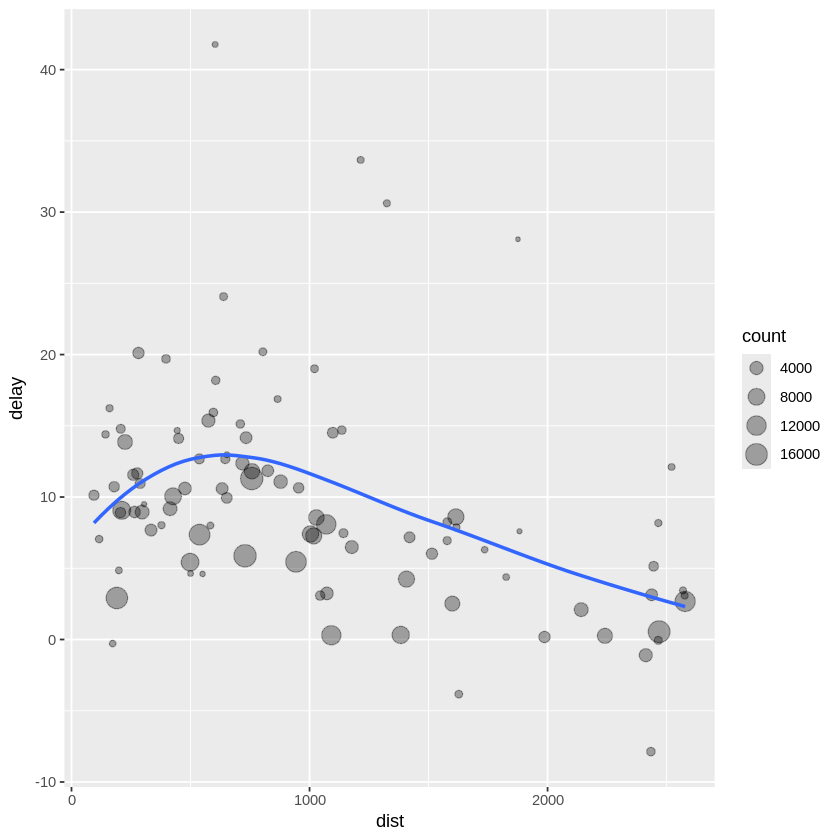

In [ ]:
ggplot(data = delay, mapping = aes(x = dist, y = delay)) +
  geom_point(aes(size = count), alpha = 1/3) +
  geom_smooth(se = FALSE)

It looks like delays increase with distance up to ~750 miles and then decrease. Maybe as flights get longer there's more ability to make up delays in the air?

## 3.4 Pipe-commando (voorbeeld 2)

Bovenstaande code kunnen we ook zonder de ' tussenvariabele' (by_dest) maken door een 'pipe' (%>%) te gebruiken:

`geom_smooth()` using method = 'loess' and formula = 'y ~ x'


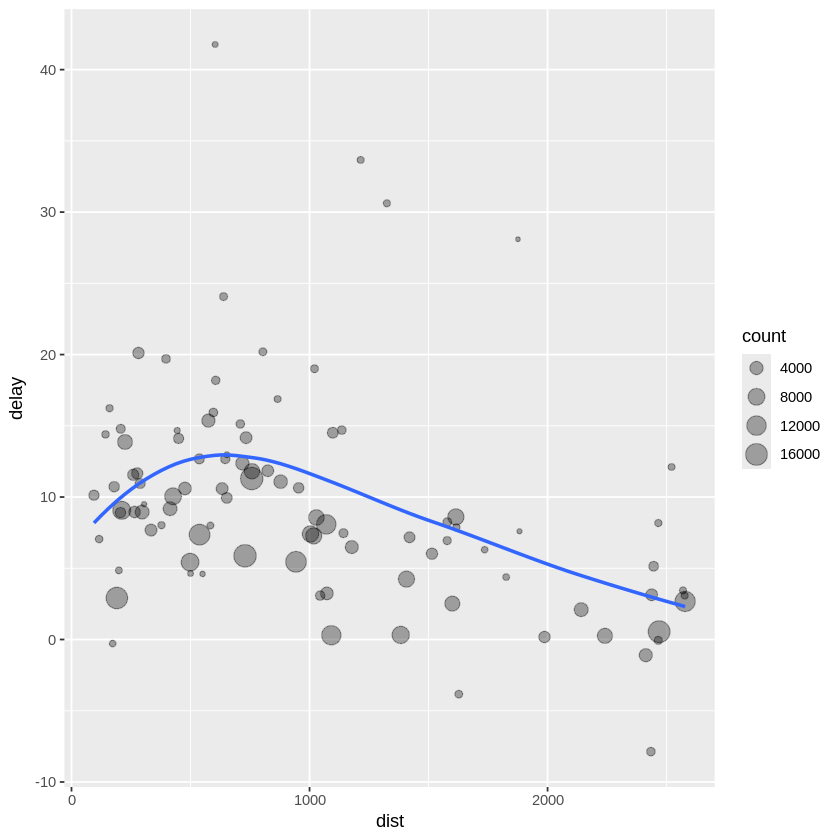

In [ ]:
delays <- nycflights13::flights %>%
  group_by(dest) %>%
  summarise(
    count = n(),
    dist = mean(distance, na.rm = TRUE),
    delay = mean(arr_delay, na.rm = TRUE)
  ) %>%
  filter(count > 20, dest != "HNL")
ggplot(data = delay, mapping = aes(x = dist, y = delay)) +
  geom_point(aes(size = count), alpha = 1/3) +
  geom_smooth(se = FALSE)

## 3.5.3 Slice-functions
Met een slice-functie kun je een specifieke rij of rijen uit je dataset selecteren. Er zijn 5 slice-functies:<br>
<ul>
<li>slice_head</li>
<li>slice_tail</li>
<li>slice_min</li>
<li>slice_max</li>
<li>slice_sample</li>
</ul>
<p>
For example, the following code finds the flights that are most delayed upon arrival at each destination:


In [ ]:
delayed <- nycflights13::flights |> group_by(dest) |>
  slice_max(arr_delay, n = 1) |>
  relocate(dest)
delayed

dest,year,month,day,dep_time,sched_dep_time,dep_delay,arr_time,sched_arr_time,arr_delay,carrier,flight,tailnum,origin,air_time,distance,hour,minute,time_hour
<chr>,<int>,<int>,<int>,<int>,<int>,<dbl>,<int>,<int>,<dbl>,<chr>,<int>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dttm>
ABQ,2013,7,22,2145,2007,98,132,2259,153,B6,1505,N784JB,JFK,259,1826,20,7,2013-07-22 20:00:00
ACK,2013,7,23,1139,800,219,1250,909,221,B6,1491,N192JB,JFK,44,199,8,0,2013-07-23 08:00:00
ALB,2013,1,25,123,2000,323,229,2101,328,EV,4309,N13908,EWR,30,143,20,0,2013-01-25 20:00:00
ANC,2013,8,17,1740,1625,75,2042,2003,39,UA,887,N528UA,EWR,404,3370,16,25,2013-08-17 16:00:00
ATL,2013,7,22,2257,759,898,121,1026,895,DL,2047,N6716C,LGA,109,762,7,59,2013-07-22 07:00:00
AUS,2013,7,10,2056,1505,351,2347,1758,349,UA,503,N803UA,EWR,192,1504,15,5,2013-07-10 15:00:00
AVL,2013,8,13,1156,832,204,1417,1029,228,EV,4175,N13538,EWR,108,583,8,32,2013-08-13 08:00:00
BDL,2013,2,21,1728,1316,252,1839,1413,266,EV,4103,N16976,EWR,26,116,13,16,2013-02-21 13:00:00
BGR,2013,12,1,1504,1056,248,1628,1230,238,EV,5309,N615QX,LGA,57,378,10,56,2013-12-01 10:00:00


# Huiswerk
Maak de opgaven 1 tot en met 6 uit paragraaf 3.5.7.

## 3.5.7.1
Hoogste gemiddelde vertraging = F9 = Frontier Airlines.

In [ ]:
nycflights13::flights |>
  group_by(carrier) |>
  summarize(
    avg_delay = mean(arr_delay, na.rm = TRUE),
    n = n()
  ) |>
  arrange(desc(avg_delay))

carrier,avg_delay,n
<chr>,<dbl>,<int>
F9,21.9207048,685
FL,20.1159055,3260
EV,15.7964311,54173
YV,15.5569853,601
OO,11.9310345,32
MQ,10.7747334,26397
WN,9.6491199,12275
B6,9.4579733,54635
9E,7.3796692,18460


## 3.5.7.2
Find the flights that are most delayed upon departure to each destination.

In [ ]:
nycflights13::flights |>
  group_by(dest) |>
  slice_max(dep_delay, n = 1) |>
  select(dest, carrier, flight, dep_delay, month, day)

dest,carrier,flight,dep_delay,month,day
<chr>,<chr>,<int>,<dbl>,<int>,<int>
ABQ,B6,65,142,12,14
ACK,B6,1491,219,7,23
ALB,EV,4309,323,1,25
ANC,UA,887,75,8,17
ATL,DL,2047,898,7,22
AUS,UA,503,351,7,10
AVL,EV,4519,222,6,14
BDL,EV,4103,252,2,21
BGR,EV,5309,248,12,1


## 3.5.7.3
How do delays vary over the course of the day? Illustrate your answer with a plot.

Warning message:
“Using `size` aesthetic for lines was deprecated in ggplot2 3.4.0.
ℹ Please use `linewidth` instead.”
Warning message:
“Removed 2 rows containing missing values or values outside the scale range
(`geom_line()`).”
Warning message:
“Removed 2 rows containing missing values or values outside the scale range
(`geom_point()`).”


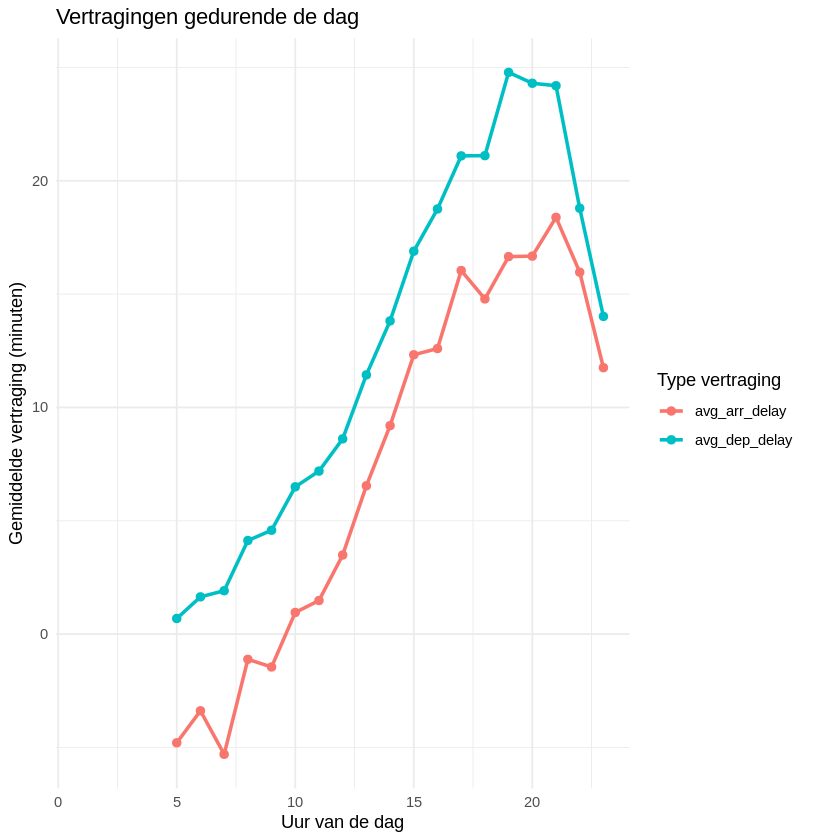

In [ ]:
delays_by_hour <- nycflights13::flights |>
  group_by(hour) |>
  summarise(
    avg_dep_delay = mean(dep_delay, na.rm = TRUE),
    avg_arr_delay = mean(arr_delay, na.rm = TRUE)
  )

delays_by_hour |>
  pivot_longer(cols = c(avg_dep_delay, avg_arr_delay),
               names_to = "delay_type",
               values_to = "avg_delay") |>
  ggplot(aes(x = hour, y = avg_delay, color = delay_type)) +
  geom_line(size = 1) +
  geom_point(size = 2) +
  labs(
    title = "Vertragingen gedurende de dag",
    x = "Uur van de dag",
    y = "Gemiddelde vertraging (minuten)",
    color = "Type vertraging"
  ) +
  theme_minimal()

## 3.5.7.4
What happens if you supply a negative n to slice_min() and friends?
<p>
De sortering is nu niet op basis van de grootste vertraging bij vertrek, maar de grootste NEGATIEVE vertraging =  'grootste' eerder vertrek dan gepland.


In [ ]:
nycflights13::flights |>
  group_by(dest) |>
  slice_min(dep_delay, n = -1)

year,month,day,dep_time,sched_dep_time,dep_delay,arr_time,sched_arr_time,arr_delay,carrier,flight,tailnum,origin,dest,air_time,distance,hour,minute,time_hour
<int>,<int>,<int>,<int>,<int>,<dbl>,<int>,<int>,<dbl>,<chr>,<int>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dttm>
2013,11,20,1948,2000,-12,2236,2303,-27,B6,65,N579JB,JFK,ABQ,259,1826,20,0,2013-11-20 20:00:00
2013,9,10,1949,2001,-12,2225,2248,-23,B6,65,N535JB,JFK,ABQ,232,1826,20,1,2013-09-10 20:00:00
2013,11,1,1950,2000,-10,2226,2303,-37,B6,65,N659JB,JFK,ABQ,253,1826,20,0,2013-11-01 20:00:00
2013,11,5,1950,2000,-10,2310,2303,7,B6,65,N593JB,JFK,ABQ,284,1826,20,0,2013-11-05 20:00:00
2013,11,15,1950,2000,-10,2304,2303,1,B6,65,N510JB,JFK,ABQ,281,1826,20,0,2013-11-15 20:00:00
2013,12,28,1951,2001,-10,2243,2304,-21,B6,65,N760JB,JFK,ABQ,264,1826,20,1,2013-12-28 20:00:00
2013,9,18,1951,2001,-10,2210,2248,-38,B6,65,N552JB,JFK,ABQ,232,1826,20,1,2013-09-18 20:00:00
2013,10,19,1950,1959,-9,2236,2246,-10,B6,65,N635JB,JFK,ABQ,262,1826,19,59,2013-10-19 19:00:00
2013,10,26,1950,1959,-9,2217,2246,-29,B6,65,N594JB,JFK,ABQ,244,1826,19,59,2013-10-26 19:00:00


## 3.5.7.5
Explain what count() does in terms of the dplyr verbs you just learned. What does the sort argument to count() do?

In [ ]:
# count() is equivalent aan:
nycflights13::flights |>
  group_by(carrier) |>
  summarize(n = n())

# Dit is hetzelfde als:
nycflights13::flights |>
  count(carrier)

carrier,n
<chr>,<int>
9E,18460
AA,32729
AS,714
B6,54635
DL,48110
EV,54173
F9,685
FL,3260
HA,342


carrier,n
<chr>,<int>
9E,18460
AA,32729
AS,714
B6,54635
DL,48110
EV,54173
F9,685
FL,3260
HA,342


In [ ]:
# Met sort argument:
nycflights13::flights |>
  count(carrier, sort = TRUE)

# Dit is equivalent aan:
nycflights13::flights |>
  group_by(carrier) |>
  summarize(n = n()) |>
  arrange(desc(n))

carrier,n
<chr>,<int>
UA,58665
B6,54635
EV,54173
DL,48110
AA,32729
MQ,26397
US,20536
9E,18460
WN,12275


carrier,n
<chr>,<int>
UA,58665
B6,54635
EV,54173
DL,48110
AA,32729
MQ,26397
US,20536
9E,18460
WN,12275


## 3.5.7.6a
Write down what you think the output will look like, then check if you were correct, and describe what group_by() does.


In [ ]:
df <- tibble(
  x = 1:5,
  y = c("a", "b", "a", "a", "b"),
  z = c("K", "K", "L", "L", "K")
)

df |>
  group_by(y)

x,y,z
<int>,<chr>,<chr>
1,a,K
2,b,K
3,a,L
4,a,L
5,b,K


De output zal er ongeveer zo uitzien als de originele dataframe, maar met een extra regel boven de tabel die aangeeft: A grouped_df 5 x 3.
<br>
Group_by(y) groepeert de data op basis van de kolom y.

## 3.5.7.6b
Write down what you think the output will look like, then check if you were correct, and describe what arrange() does. Also, comment on how it's different from the group_by() in part (a).

In [ ]:
df |>
  arrange(y)

x,y,z
<int>,<chr>,<chr>
1,a,K
3,a,L
4,a,L
2,b,K
5,b,K


Uitleg: met arrange wordt kolom y op alfabetische volgorde gezet, met group by wordt het gecategoriseerd op een kolomwaarde (groep).

## 3.5.7.6c
Write down what you think the output will look like, then check if you were correct, and describe what the pipeline does.

In [ ]:
df |>
  group_by(y) |>
  summarize(mean_x = mean(x))

y,mean_x
<chr>,<dbl>
a,2.666667
b,3.500000


Je groepeert op kolom y, dus hou je alleen a en b over. Per regel (=groep) berekent summarize de gemiddelde x-waarde:<br>
- voor groep a: (1 + 3 + 4)/3 = 2,667
- voor groep b: (2 + 5)/2 = 3,5

**Wat doet de pipeline:**
1. Groepeert de data op kolom y.
2. Berekent voor elke groep het gemiddelde van kolom x.
3. Retourneert een samengevatte tabel met één rij per groep.  

## 3.5.7.6d
Write down what you think the output will look like, then check if you were correct, and describe what the pipeline does. Then, comment on what the message says.

In [ ]:
df |>
  group_by(y, z) |>
  summarize(mean_x = mean(x))

`summarise()` has grouped output by 'y'. You can override using the `.groups`
argument.


y,z,mean_x
<chr>,<chr>,<dbl>
a,K,1.0
a,L,3.5
b,K,3.5


**Wat doet de pipeline:**

1. Groepeert de data op beide kolommen y én z
2. Berekent voor elke unieke combinatie van y en z het gemiddelde van x
3. Retourneert een tabel met één rij per combinatie

**Boodschap/Message:**<br>
R geeft een waarschuwing:<br>*summarise() has grouped output by 'y'. You can override using the .groups argument.*

Dit betekent dat na de summarize de data eerst gegroepeerd is op y (daarna op z).<br>
Dit kan onverwachte effecten hebben bij verdere bewerkingen.

## 3.5.7.6e
Write down what you think the output will look like, then check if you were correct, and describe what the pipeline does. How is the output different from the one in part (d)?

In [ ]:
df |>
  group_by(y, z) |>
  summarize(mean_x = mean(x), .groups = "drop")

y,z,mean_x
<chr>,<chr>,<dbl>
a,K,1.0
a,L,3.5
b,K,3.5


**Verschil met (d):**<br>
Door .groups = "drop" toe te voegen wordt de groepering volledig verwijderd na de summarize operatie.<br>
De output is een "normale" tibble zonder groepering.
<br>
Dit voorkomt onverwachte effecten bij verdere bewerkingen en is vaak een best practice.

## 3.5.7.6f
Write down what you think the outputs will look like, then check if you were correct, and describe what each pipeline does. How are the outputs of the two pipelines different?

In [ ]:
# Pipeline 1
df |>
  group_by(y, z) |>
  summarize(mean_x = mean(x))

# Pipeline 2
df |>
  group_by(y, z) |>
  mutate(mean_x = mean(x))

`summarise()` has grouped output by 'y'. You can override using the `.groups`
argument.


y,z,mean_x
<chr>,<chr>,<dbl>
a,K,1.0
a,L,3.5
b,K,3.5


x,y,z,mean_x
<int>,<chr>,<chr>,<dbl>
1,a,K,1.0
2,b,K,3.5
3,a,L,3.5
4,a,L,3.5
5,b,K,3.5


**Pipeline 1 (met summarize):**<br>
- Geeft 3 rijen (één per unieke combinatie van y en z)
- Kolommen: y, z, mean_x
- De originele rijen worden samengevoegd tot samenvattingsstatistieken

**Pipeline 2 (met mutate):**<br>
- Behoudt alle 5 originele rijen
- Voegt een nieuwe kolom `mean_x` toe met het gemiddelde per groep
- Elke rij in dezelfde groep krijgt dezelfde mean_x waarde
- Kolommen: x, y, z, mean_x

**Kernverschil:**<br>
- summarize() --> reduceert het aantal rijen tot één per groep.
- mutate() --> behoudt alle rijen en voegt berekende waarden toe als nieuwe kolom.

# Nog meer oefenen

- Maak een ' scatterplot' van de gemiddelde vertraging bij aankomst per vlucht.<br>
- Maak een overzicht van de gemiddelde vertraging bij aankomst per dag.<br>
- Maak een overzicht van de standaardafwijking van de 'distance' (= afstand in miles) per bestemming.<br>Sorteer in ' descending order' = grootste eerst.<br>
- Maak een overzicht dat per dag in 2013 de eerste en de laatste vertrokken vlucht laat zien.<br>
- Maak een telling van het aantal unieke maatschappijen dat naar een bestemming vliegt. Sorteer in 'descending order'.<br>
- Maak een overzicht dat per vliegmaatschappij laat zien naar hoeveel bestemmingen deze maatschappij vliegt. Sorteer alfabetisch.<br>
- Maak een top tien van vliegtuigen (gebruik tailnum) die het meest gevlogen hebben in 2013.<br>
- Maak een overzicht dat per dag laat zien hoeveel vluchten er voor 5 uur 's ochtends zijn vertrokken.<br>
- Maak een berekening van het % vluchten per dag met meer dan 1 uur vertraging.




En nog wat oefeningen die horen bij paragraaf 3.5:<br>
- Vind de populairste bestemming.<br>
- Welk vliegtuignummer (tailnum) heeft gemiddeld de meeste vertraging?<br>
- Op welk tijdstip op de dag is de kans op vertraging het grootst? Op welk het kleinst?
- Wat is de beste vliegmaatschappij = de maatschappij met de minste vertraging?

# 3.6 Case Study met Summarize en Group By
We gebruiken een dataset over honkbal (Amerikaans: baseball) als voorbeeld: de Lahman Batting-set.

In [ ]:
Lahman::Batting

playerID,yearID,stint,teamID,lgID,G,AB,R,H,X2B,⋯,RBI,SB,CS,BB,SO,IBB,HBP,SH,SF,GIDP
<chr>,<int>,<int>,<fct>,<fct>,<int>,<int>,<int>,<int>,<int>,⋯,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>
aardsda01,2004,1,SFN,NL,11,0,0,0,0,⋯,0,0,0,0,0,0,0,0,0,0
aardsda01,2006,1,CHN,NL,45,2,0,0,0,⋯,0,0,0,0,0,0,0,1,0,0
aardsda01,2007,1,CHA,AL,25,0,0,0,0,⋯,0,0,0,0,0,0,0,0,0,0
aardsda01,2008,1,BOS,AL,47,1,0,0,0,⋯,0,0,0,0,1,0,0,0,0,0
aardsda01,2009,1,SEA,AL,73,0,0,0,0,⋯,0,0,0,0,0,0,0,0,0,0
aardsda01,2010,1,SEA,AL,53,0,0,0,0,⋯,0,0,0,0,0,0,0,0,0,0
aardsda01,2012,1,NYA,AL,1,0,0,0,0,⋯,0,0,0,0,0,0,0,0,0,0
aardsda01,2013,1,NYN,NL,43,0,0,0,0,⋯,0,0,0,0,0,0,0,0,0,0
aardsda01,2015,1,ATL,NL,33,1,0,0,0,⋯,0,0,0,0,1,0,0,0,0,0


Specifically, we will compare what proportion of times a player gets a hit (H) vs. the number of times they try to put the ball in play (AB):

In [ ]:
batters <- Lahman::Batting |>
  group_by(playerID) |>
  summarize(
    performance = sum(H, na.rm = TRUE) / sum(AB, na.rm = TRUE),
    n = sum(AB, na.rm = TRUE)
  )
batters

playerID,performance,n
<chr>,<dbl>,<int>
aardsda01,0.00000000,4
aaronha01,0.30499838,12364
aaronto01,0.22881356,944
aasedo01,0.00000000,5
abadan01,0.09523810,21
abadfe01,0.11111111,9
abadijo01,0.22448980,49
abbated01,0.25361367,3044
abbeybe01,0.16888889,225


Even een mooi grafiekje:

`geom_smooth()` using method = 'gam' and formula = 'y ~ s(x, bs = "cs")'


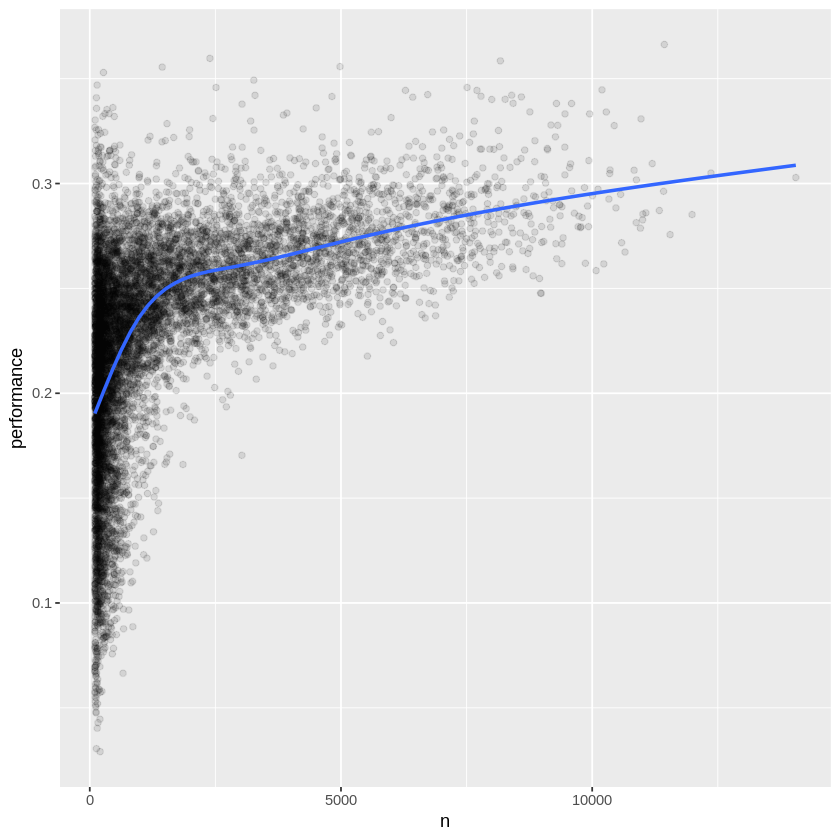

In [ ]:
batters |>
  filter(n > 100) |>
  ggplot(aes(x = n, y = performance)) +
  geom_point(alpha = 1 / 10) +
  geom_smooth(se = FALSE)

Conclusie:<br>
- De spreiding in slaggemiddelde (batting average) is veel groter bij spelers die minder vaak slaan.
- Hoe vaker je slaat, hoe beter je slaggemiddelde (of andersom: de spelers met een hoger slaggemiddelde komen vaker aan de beurt?)
<p>

Kunnen we ook een lijstje maken met de 'beste' honkballers? Laten we het eens proberen met de functie arrange:

In [ ]:
batters |>
  arrange(desc(performance))

playerID,performance,n
<chr>,<dbl>,<int>
abramge01,1,1
alberan01,1,1
banisje01,1,1
bartocl01,1,1
bassdo01,1,1
birasst01,1,2
bruneju01,1,1
burnscb01,1,1
cammaer01,1,1


Klopt dit?

Voor een betere oplossing:<br>
https://www.evanmiller.org/how-not-to-sort-by-average-rating.html <br>

Of (zie onder):<br>
http://varianceexplained.org/r/empirical_bayes_baseball/

## Working with batting averages
https://lahman.r-forge.r-project.org/doc/Batting.html

In [ ]:
career <- Lahman::Batting %>%
  filter(AB > 0) %>%
  anti_join(Lahman::Pitching, by = "playerID") %>%
  group_by(playerID) %>%
  summarize(H = sum(H), AB = sum(AB)) %>%
  mutate(average = H / AB)
career

playerID,H,AB,average
<chr>,<int>,<int>,<dbl>
aaronha01,3771,12364,0.3049984
aaronto01,216,944,0.2288136
abadan01,2,21,0.0952381
abadijo01,11,49,0.2244898
abbated01,772,3044,0.2536137
abbotfr01,107,513,0.2085770
abbotje01,157,596,0.2634228
abbotku01,523,2044,0.2558708
abbotod01,13,70,0.1857143


https://lahman.r-forge.r-project.org/doc/Master.html

In [ ]:
# use names along with the player IDs
career <- Lahman::Master %>%
  tibble::as_tibble() %>%
  select(playerID, nameFirst, nameLast) %>%
  unite(name, nameFirst, nameLast, sep = " ") %>%
  inner_join(career, by = "playerID") %>%
  select(-playerID)
career

In [ ]:
# just like the graph, we have to filter for the players we actually
# have a decent estimate of
career_filtered <- career %>%
    filter(AB >= 500)

In [ ]:
m <- MASS::fitdistr(career_filtered$average, dbeta,
                    start = list(shape1 = 1, shape2 = 10))

alpha0 <- m$estimate[1]
beta0 <- m$estimate[2]

Warning message in densfun(x, parm[1], parm[2], ...):
“NaNs produced”
Warning message in densfun(x, parm[1], parm[2], ...):
“NaNs produced”
Warning message in densfun(x, parm[1], parm[2], ...):
“NaNs produced”


In [ ]:
alpha0

shape1 
78.59707

In [ ]:
beta0

shape2 
226.1642

In [ ]:
career_eb <- career %>%
    mutate(eb_estimate = (H + alpha0) / (AB + alpha0 + beta0))

In [ ]:
career_eb |>
  arrange(desc(eb_estimate))

name,H,AB,average,eb_estimate
<chr>,<int>,<int>,<dbl>,<dbl>
Rogers Hornsby,2930,8173,0.3584975,0.3548811
Shoeless Joe Jackson,1772,4981,0.3557519,0.3501098
Ed Delahanty,2597,7510,0.3458056,0.3423773
Billy Hamilton,2164,6283,0.3444215,0.3404187
Harry Heilmann,2660,7787,0.3415950,0.3384426
Willie Keeler,2932,8591,0.3412874,0.3384305
Bill Terry,2193,6428,0.3411637,0.3373946
Lou Gehrig,2721,8001,0.3400825,0.3370669
Nap Lajoie,3243,9590,0.3381648,0.3356925


Dit is toch een andere volgorde dan we eerst hadden ...